In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Path setting
DATA_DIR = './data'

def load_orl_dataset(data_dir):
    X = []
    y = []
    img_shape = None
    
    # AT&T dataset has subfolders s1 to s40
    subject_folders = sorted(glob.glob(os.path.join(data_dir, 's*')))
    
    for label, folder in enumerate(subject_folders):
        image_paths = sorted(glob.glob(os.path.join(folder, '*.pgm')) + 
                             glob.glob(os.path.join(folder, '*.png')))
        for img_path in image_paths:
            img = Image.open(img_path).convert('L') # Convert to grayscale
            if img_shape is None:
                img_shape = np.array(img).shape
            X.append(np.array(img).flatten())
            y.append(label)
            
    return np.array(X, dtype=np.float64), np.array(y), img_shape

X, y, img_shape = load_orl_dataset(DATA_DIR)
print(f"Total samples: {X.shape[0]}")
print(f"Features per image (pixels): {X.shape[1]}")
print(f"Original Image Dimensions: {img_shape}")
print(f"Min Intensity: {X.min()}, Max Intensity: {X.max()}")

Total samples: 400
Features per image (pixels): 10304
Original Image Dimensions: (112, 92)
Min Intensity: 0.0, Max Intensity: 251.0


In [2]:
def stratified_split(X, y, train_ratio=0.7, seed=42):
    np.random.seed(seed)
    train_idx, test_idx = [], []
    
    for label in np.unique(y):
        indices = np.where(y == label)[0]
        np.random.shuffle(indices)
        n_train = int(len(indices) * train_ratio)
        train_idx.extend(indices[:n_train])
        test_idx.extend(indices[n_train:])
        
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, train_ratio=0.7)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape:  {X_test.shape}")

Training set shape: (280, 10304)
Testing set shape:  (120, 10304)


In [3]:
# 1. Mean Centering
mean_face = np.mean(X_train, axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# 2. Dual-Space Eigendecomposition (N << D trick for speed)
# Covariance matrix surrogate: C_small = X_centered @ X_centered.T
C_small = np.dot(X_train_centered, X_train_centered.T) / (X_train_centered.shape[0] - 1)
eigvals_eig, eigvecs_small = np.linalg.eigh(C_small)

# Sort eigenvalues and eigenvectors descending
sorted_idx = np.argsort(eigvals_eig)[::-1]
eigvals_eig = eigvals_eig[sorted_idx]
eigvecs_small = eigvecs_small[:, sorted_idx]

# Map back to high-dimensional space
eigenfaces_eig = np.dot(X_train_centered.T, eigvecs_small)
eigenfaces_eig = eigenfaces_eig / np.linalg.norm(eigenfaces_eig, axis=0) # Normalize

# 3. Singular Value Decomposition (SVD)
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
eigenfaces_svd = Vt.T  # Principal directions from SVD

# Comparison check
print("Eigenfaces computed via Eigendecomposition and SVD.")
print(f"Top 5 Eigenvalues (Eigendecomposition): {eigvals_eig[:5]}")
print(f"Top 5 Singular Values Squared / (N-1) (SVD): {(S[:5]**2) / (X_train.shape[0] - 1)}")

Eigenfaces computed via Eigendecomposition and SVD.
Top 5 Eigenvalues (Eigendecomposition): [2832912.48795124 2096909.08898012 1121006.55841643  889607.05666612
  838097.78289012]
Top 5 Singular Values Squared / (N-1) (SVD): [2832912.48795124 2096909.08898012 1121006.55841643  889607.05666612
  838097.78289012]


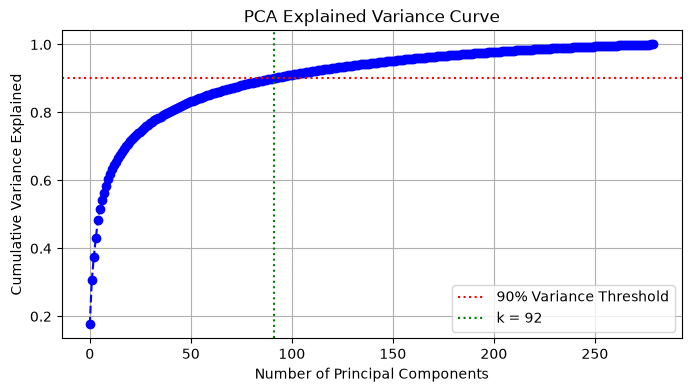

Minimum components to retain 90% variance: 92


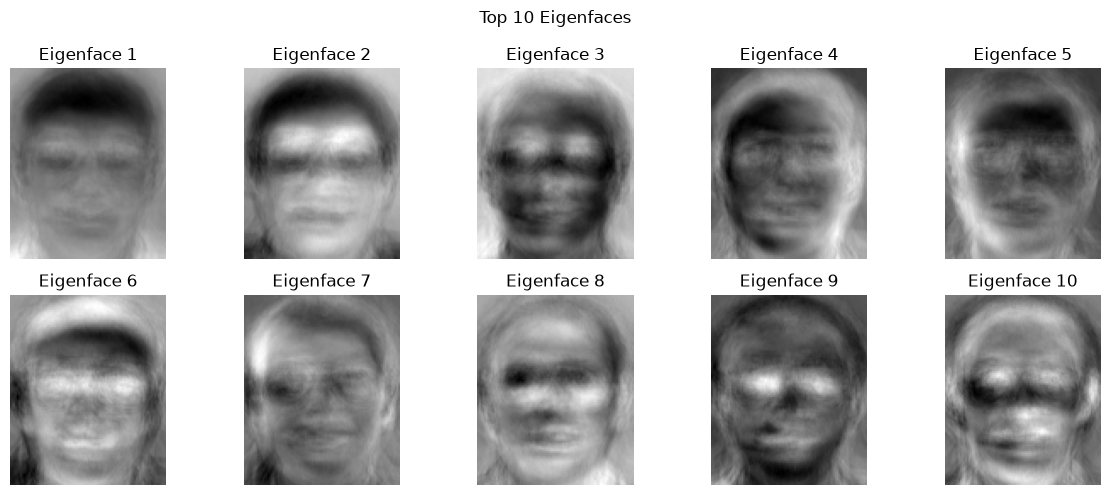

In [4]:
# Calculate Cumulative Explained Variance Ratio
var_explained = eigvals_eig / np.sum(eigvals_eig)
cum_var_explained = np.cumsum(var_explained)

# Find components for >= 90% variance
k_90 = np.argmax(cum_var_explained >= 0.90) + 1

plt.figure(figsize=(8, 4))
plt.plot(cum_var_explained, marker='o', linestyle='--', color='b')
plt.axhline(y=0.90, color='r', linestyle=':', label='90% Variance Threshold')
plt.axvline(x=k_90 - 1, color='g', linestyle=':', label=f'k = {k_90}')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.title('PCA Explained Variance Curve')
plt.legend()
plt.grid(True)
plt.savefig('explained_variance.png')
plt.show()

print(f"Minimum components to retain 90% variance: {k_90}")

# Visualize top Eigenfaces
top_k_eigenfaces = eigenfaces_eig[:, :k_90]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(top_k_eigenfaces[:, i].reshape(img_shape), cmap='gray')
    ax.set_title(f"Eigenface {i+1}")
    ax.axis('off')
plt.suptitle('Top 10 Eigenfaces')
plt.tight_layout()
plt.savefig('eigenfaces.png')
plt.show()

Original Data Storage: 22540.00 KB
Compressed Data Storage (PCA + Vectors): 7687.75 KB
Storage Savings: 65.89%


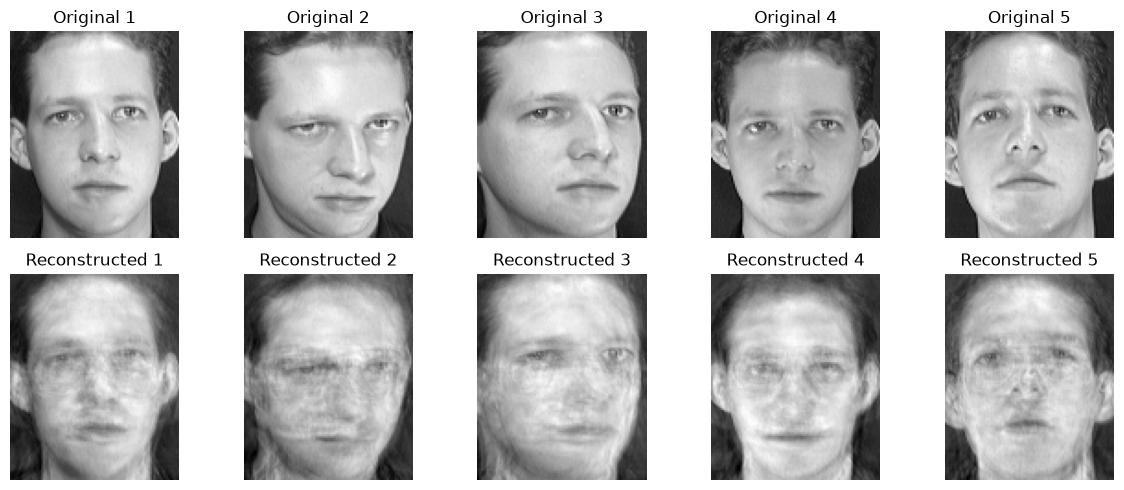

In [5]:
# Project onto PCA space
X_train_pca = np.dot(X_train_centered, top_k_eigenfaces)
X_test_pca = np.dot(X_test_centered, top_k_eigenfaces)

# Reconstruct faces
X_train_reconstructed = np.dot(X_train_pca, top_k_eigenfaces.T) + mean_face

# Storage comparison
orig_storage = X_train.nbytes / 1024  # in KB
pca_storage = (X_train_pca.nbytes + top_k_eigenfaces.nbytes + mean_face.nbytes) / 1024

print(f"Original Data Storage: {orig_storage:.2f} KB")
print(f"Compressed Data Storage (PCA + Vectors): {pca_storage:.2f} KB")
print(f"Storage Savings: {100 * (1 - pca_storage / orig_storage):.2f}%")

# Visualize Sample Reconstruction
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    axes[0, i].imshow(X_train[i].reshape(img_shape), cmap='gray')
    axes[0, i].set_title(f"Original {i+1}")
    axes[0, i].axis('off')
    
    axes[1, i].imshow(X_train_reconstructed[i].reshape(img_shape), cmap='gray')
    axes[1, i].set_title(f"Reconstructed {i+1}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('reconstruction_comparison.png')
plt.show()

In [6]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b)**2, axis=1))

def predict_nn(X_tr, y_tr, X_te):
    predictions = []
    for test_vec in X_te:
        distances = euclidean_distance(X_tr, test_vec)
        closest_idx = np.argmin(distances)
        predictions.append(y_tr[closest_idx])
    return np.array(predictions)

# 1. Similarity matching on PCA space
y_pred_pca = predict_nn(X_train_pca, y_train, X_test_pca)
acc_pca = np.mean(y_pred_pca == y_test)

# 2. Similarity matching on Raw Pixels
y_pred_raw = predict_nn(X_train, y_train, X_test)
acc_raw = np.mean(y_pred_raw == y_test)

print(f"1-NN Accuracy on Raw Pixels (Dimensions: {X_train.shape[1]}): {acc_raw * 100:.2f}%")
print(f"1-NN Accuracy on PCA Space (Dimensions: {k_90}): {acc_pca * 100:.2f}%")

1-NN Accuracy on Raw Pixels (Dimensions: 10304): 98.33%
1-NN Accuracy on PCA Space (Dimensions: 92): 98.33%


In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Baseline Baseline Matching Accuracy
models = {
    "Baseline 1-NN (PCA Euclidean)": None,
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Support Vector Machine (RBF)": SVC(kernel='rbf', C=10)
}

results = {"Baseline 1-NN (PCA Euclidean)": acc_pca}

for name, model in models.items():
    if model is None:
        continue
    model.fit(X_train_pca, y_train)
    preds = model.predict(X_test_pca)
    acc = accuracy_score(y_test, preds)
    results[name] = acc

print("--- Final Model Comparison ---")
for model_name, accuracy in results.items():
    print(f"{model_name:30s}: {accuracy * 100:.2f}%")

--- Final Model Comparison ---
Baseline 1-NN (PCA Euclidean) : 98.33%
KNN (k=3)                     : 92.50%
Logistic Regression           : 98.33%
Support Vector Machine (RBF)  : 100.00%
